# EN4554 Assignment 2: Neural Networks and CNNs on CIFAR-10

**Name:** Walgampaya H.K.B. 

 **Index number:** 220675T

**GitHub:** https://github.com/HimethW/EN4554-Assignment_2-on-CNNs

I split the 50k CIFAR-10 training images into 45k for training and 5k for validation (with a fixed seed), and normalise each channel using the mean and std of the 45k training images. The test set is only used once, at the end of Task 4. Setting `QUICK_RUN = True` trains everything for just one epoch, which is handy for checking that the notebook runs on Colab.

In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

QUICK_RUN = False
SEED = 0
DATA_DIR = "./data"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def n_epochs(n):
    return 1 if QUICK_RUN else n


set_seed()
torch.backends.cudnn.benchmark = True
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]),
})

In [2]:
cifar = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
images = torch.from_numpy(cifar.data).permute(0, 3, 1, 2).float() / 255
labels = torch.tensor(cifar.targets)

perm = torch.randperm(len(images), generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = perm[:45_000], perm[45_000:]
MEAN = images[train_idx].mean(dim=(0, 2, 3))
STD = images[train_idx].std(dim=(0, 2, 3))


def normalize(x):
    return (x - MEAN.view(1, 3, 1, 1)) / STD.view(1, 3, 1, 1)


# the whole split lives on the GPU, so batching needs no DataLoader
X_train, y_train = normalize(images[train_idx]).to(device), labels[train_idx].to(device)
X_val, y_val = normalize(images[val_idx]).to(device), labels[val_idx].to(device)
del images, labels


def batches(X, y, batch_size, shuffle=False, gen=None):
    order = torch.randperm(len(X), generator=gen).to(X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), batch_size):
        idx = order[i:i + batch_size]
        yield X[idx], y[idx]


print("train", tuple(X_train.shape), "val", tuple(X_val.shape))
print("mean", MEAN.numpy().round(4), "std", STD.numpy().round(4))

train (45000, 3, 32, 32) val (5000, 3, 32, 32)
mean [0.4912 0.482  0.4464] std [0.2472 0.2436 0.2617]


# Task 1: Backpropagation

## 1(a) Linear, ReLU and softmax cross-entropy

Each layer has two methods. `forward` computes the output and saves what it needs for later. `backward` gets the gradient from the layer above, works out the gradients of its own weights, and passes the gradient down to the layer below. No autograd is used.

Here $dy$ means the gradient of the loss with respect to $y$, and $N$ is the batch size.

| Layer | Forward | Backward |
|---|---|---|
| Linear | $y = xW^\top + b$ | $dW = dy^\top x$, $\;db = $ sum of $dy$ over the batch, $\;dx = dy\,W$ |
| ReLU | $y = \max(0, x)$ | $dx = dy$ where $x > 0$, and $0$ elsewhere |
| Softmax + cross-entropy | $L = -\frac{1}{N}\sum \log(p_\text{true class})$ | $dz = \frac{1}{N}\big(p - \text{onehot}(\text{label})\big)$ |

In the softmax I subtract the largest logit first so `exp` can't overflow. Weights start with Kaiming init (std $= \sqrt{2/d_\text{in}}$) for ReLU, or Xavier init (std $= \sqrt{2/(d_\text{in} + d_\text{out})}$) for the sigmoid network in 1(d).

In [3]:
class Linear:
    def __init__(self, n_in, n_out, init="kaiming", dtype=torch.float32):
        std = math.sqrt(2 / n_in) if init == "kaiming" else math.sqrt(2 / (n_in + n_out))
        self.W = (torch.randn(n_out, n_in, dtype=dtype) * std).to(device)
        self.b = torch.zeros(n_out, dtype=dtype, device=device)

    def forward(self, x):
        self.x = x
        return x @ self.W.T + self.b

    def backward(self, dout):
        self.dW = dout.T @ self.x
        self.db = dout.sum(dim=0)
        return dout @ self.W


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values  # log-sum-exp trick
        log_p = z - z.exp().sum(dim=1, keepdim=True).log()
        self.p, self.y = log_p.exp(), y
        self.rows = torch.arange(len(y), device=y.device)
        return -log_p[self.rows, y].mean()

    def backward(self):
        grad = self.p.clone()
        grad[self.rows, self.y] -= 1
        return grad / len(self.y)


class MLP:
    def __init__(self, sizes, activation=ReLU, init="kaiming", dtype=torch.float32):
        self.linears = [Linear(a, b, init, dtype) for a, b in zip(sizes[:-1], sizes[1:])]
        self.layers = []
        for lin in self.linears:
            self.layers += [lin, activation()]
        self.layers.pop()  # the last layer outputs logits
        self.criterion = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.criterion.forward(self.forward(x), y)

    def backward(self):
        grad = self.criterion.backward()
        for layer in reversed(self.layers):
            grad = layer.backward(grad)

    def params(self):
        return [p for lin in self.linears for p in (lin.W, lin.b)]

    def grads(self):
        return [g for lin in self.linears for g in (lin.dW, lin.db)]

## 1(b) Gradient check

I compare my gradients for a 3072 → 512 → 256 → 10 MLP with two references: autograd (the same weights loaded into `nn.Linear` layers) and centred finite differences, $\frac{L(\theta + h) - L(\theta - h)}{2h}$ with $h = 10^{-6}$. Finite differences need two forward passes per weight, so I only check 20 random weights in each tensor. Everything is in float64 because float32 isn't precise enough for finite differences. The relative error is $\|g - \hat g\| \,/\, \max(\|g\|, \|\hat g\|)$.

In [4]:
def rel_error(a, b):
    return ((a - b).norm() / torch.maximum(a.norm(), b.norm())).item()


def autograd_grads(mlp, x, y):
    layers = []
    for lin in mlp.linears:
        layer = nn.Linear(lin.W.shape[1], lin.W.shape[0]).to(device, lin.W.dtype)
        with torch.no_grad():
            layer.weight.copy_(lin.W)
            layer.bias.copy_(lin.b)
        layers += [layer, nn.ReLU()]
    net = nn.Sequential(*layers[:-1])
    F.cross_entropy(net(x), y).backward()
    return [p.grad for p in net.parameters()]


def finite_diff_grads(mlp, x, y, n_entries=20, h=1e-6):
    estimates = []
    for p in mlp.params():
        flat = p.view(-1)
        idx = torch.randperm(flat.numel())[:n_entries]
        est = torch.empty(len(idx), dtype=p.dtype)
        for k, i in enumerate(idx):
            old = flat[i].item()
            flat[i] = old + h
            loss_plus = mlp.loss(x, y).item()
            flat[i] = old - h
            loss_minus = mlp.loss(x, y).item()
            flat[i] = old
            est[k] = (loss_plus - loss_minus) / (2 * h)
        estimates.append((idx, est))
    return estimates


set_seed()
mlp = MLP([3072, 512, 256, 10], dtype=torch.float64)
x, y = X_train[:64].flatten(1).double(), y_train[:64]
mlp.loss(x, y)
mlp.backward()
auto = autograd_grads(mlp, x, y)
numeric = finite_diff_grads(mlp, x, y)

print(f"{'param':<7}{'shape':<14}{'vs autograd':>13}{'allclose':>10}{'vs finite diff':>17}{'allclose':>10}")
for i, (g, a, (idx, est)) in enumerate(zip(mlp.grads(), auto, numeric)):
    name = ("W", "b")[i % 2] + str(i // 2 + 1)
    g_sub = g.view(-1)[idx].cpu()
    print(f"{name:<7}{str(tuple(g.shape)):<14}{rel_error(g, a):>13.1e}{str(torch.allclose(g, a)):>10}"
          f"{rel_error(g_sub, est):>17.1e}{str(torch.allclose(g_sub, est)):>10}")

param  shape           vs autograd  allclose   vs finite diff  allclose
W1     (512, 3072)         6.3e-16      True          1.7e-08      True
b1     (512,)              5.4e-16      True          1.7e-08      True
W2     (256, 512)          8.0e-16      True          2.2e-08      True
b2     (256,)              4.0e-16      True          1.1e-08      True
W3     (10, 256)           7.5e-16      True          1.7e-09      True
b3     (10,)               3.3e-16      True          2.1e-09      True


All the relative errors against autograd are around $10^{-16}$, which is just float64 rounding, so my backward pass gives the same gradients as autograd. Against finite differences the errors are around $10^{-8}$ to $10^{-9}$. They are a bit bigger only because the finite difference is itself an approximation, not because the gradients are wrong. `torch.allclose` is True for every parameter in both checks, so the manual backpropagation is correct.

## 1(c) Training with SGD

The same MLP is trained on the flattened images with plain SGD ($\theta \leftarrow \theta - \eta\, \nabla L$), batch size 128, learning rate 0.05, for 30 epochs. I picked the learning rate by trying a few values and comparing validation accuracy.

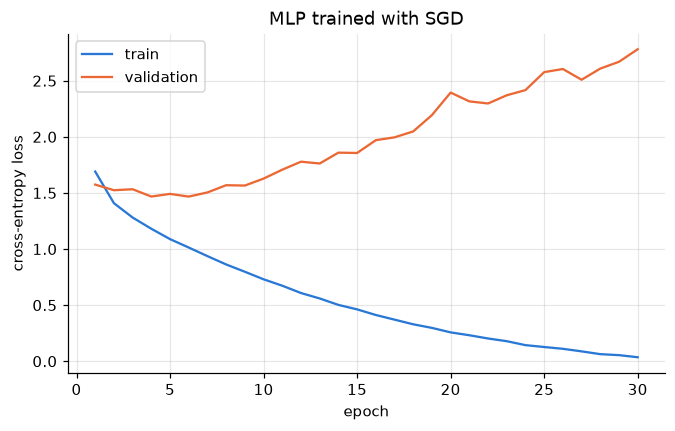

train accuracy 97.29%
validation accuracy 51.14%


In [5]:
def evaluate(mlp, X, y, batch_size=1000):
    loss_sum, correct = 0.0, 0
    for xb, yb in batches(X, y, batch_size):
        logits = mlp.forward(xb.flatten(1))
        loss_sum += mlp.criterion.forward(logits, yb).item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
    return loss_sum / len(X), correct / len(X)


def train_sgd(mlp, epochs, lr, batch_size=128):
    gen = torch.Generator().manual_seed(SEED)
    train_loss, val_loss = [], []
    for _ in range(epochs):
        losses = []
        for xb, yb in batches(X_train, y_train, batch_size, shuffle=True, gen=gen):
            losses.append(mlp.loss(xb.flatten(1), yb).item())
            mlp.backward()
            for p, g in zip(mlp.params(), mlp.grads()):
                p -= lr * g
        train_loss.append(np.mean(losses))
        val_loss.append(evaluate(mlp, X_val, y_val)[0])
    return train_loss, val_loss


set_seed()
mlp = MLP([3072, 512, 256, 10])
train_loss, val_loss = train_sgd(mlp, n_epochs(30), lr=0.05)

epochs = range(1, len(train_loss) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, train_loss, label="train")
plt.plot(epochs, val_loss, label="validation")
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("MLP trained with SGD")
plt.legend()
plt.show()

print(f"train accuracy {evaluate(mlp, X_train, y_train)[1]:.2%}")
print(f"validation accuracy {evaluate(mlp, X_val, y_val)[1]:.2%}")

The training loss keeps falling to almost zero, but the validation loss is lowest around epochs 4 to 6 (about 1.47) and then climbs to about 2.8. So the MLP starts overfitting after only a few epochs, and by the end it gets 97% of the training images right but only 51% of the validation images. Validation accuracy stays at about 50% after epoch 6 even though the validation loss goes up, because the network becomes more and more confident on the images it gets wrong. An MLP treats an image as a flat list of 3072 numbers and doesn't know which pixels are next to each other, so it ends up memorising the training set instead of learning features that generalise.

## 1(d) Gradient norms at initialisation

I build a 10-layer MLP (3072 → 256 → … → 256 → 10), run one backward pass on 512 images and plot the norm of each layer's weight gradient. This is done once with sigmoid (Xavier init) and once with ReLU (Kaiming init). The sigmoid backward is $dx = dy \cdot \sigma(x)\big(1 - \sigma(x)\big)$.

sigmoid (Xavier init)  layer 1: 1.2e-05   layer 10: 2.3e+00
ReLU (Kaiming init)    layer 1: 4.5e+00   layer 10: 5.9e+00


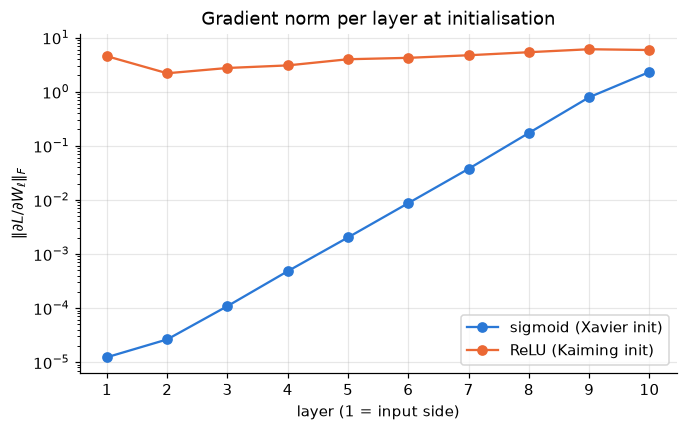

In [6]:
class Sigmoid:
    def forward(self, x):
        self.out = torch.sigmoid(x)
        return self.out

    def backward(self, dout):
        return dout * self.out * (1 - self.out)


def layer_grad_norms(activation, init):
    set_seed()
    mlp = MLP([3072] + [256] * 9 + [10], activation, init)
    mlp.loss(X_train[:512].flatten(1), y_train[:512])
    mlp.backward()
    return [lin.dW.norm().item() for lin in mlp.linears]


plt.figure(figsize=(7, 4))
for name, act, init in [("sigmoid (Xavier init)", Sigmoid, "xavier"), ("ReLU (Kaiming init)", ReLU, "kaiming")]:
    norms = layer_grad_norms(act, init)
    plt.semilogy(range(1, 11), norms, marker="o", label=name)
    print(f"{name:<22} layer 1: {norms[0]:.1e}   layer 10: {norms[-1]:.1e}")
plt.xticks(range(1, 11))
plt.xlabel("layer (1 = input side)")
plt.ylabel(r"$\|\partial L / \partial W_\ell\|_F$")
plt.title("Gradient norm per layer at initialisation")
plt.legend()
plt.show()

With sigmoid, the gradient norm shrinks by about 4x for every layer we go back, from about 2 at layer 10 to about $10^{-5}$ at layer 1, so the first layers would barely learn. This is the vanishing gradient problem: the sigmoid's derivative is at most 0.25, and backpropagation multiplies by it once per layer, so the gradient shrinks exponentially with depth. ReLU's derivative is exactly 1 wherever the unit is active, and Kaiming init keeps the signal about the same size from layer to layer, so its gradient norms stay between about 2 and 6 in every layer. That's why deep networks use ReLU with a matching initialisation instead of sigmoid.

# Task 2: Optimizers

## 2(a) SGD with momentum and Adam

Both optimizers subclass `torch.optim.Optimizer` and follow the same update rules as PyTorch, where $g$ is the gradient and $\eta$ the learning rate:

- SGD with momentum: $\;v \leftarrow \mu v + g, \;\; \theta \leftarrow \theta - \eta v$ (with $\mu = 0$ this is plain SGD)
- Adam: $\;m \leftarrow \beta_1 m + (1-\beta_1) g, \;\; v \leftarrow \beta_2 v + (1-\beta_2) g^2, \;\; \hat m = \frac{m}{1-\beta_1^t}, \;\; \hat v = \frac{v}{1-\beta_2^t}, \;\; \theta \leftarrow \theta - \eta \frac{\hat m}{\sqrt{\hat v} + \epsilon}$

The bias correction ($\hat m$, $\hat v$) matters early on: $m$ and $v$ start at zero, so without it the first steps would be much too small.

In [7]:
class SGDMomentum(torch.optim.Optimizer):
    def __init__(self, params, lr, momentum=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                d = p.grad
                if group["momentum"]:
                    state = self.state[p]
                    if "v" not in state:
                        state["v"] = d.clone()
                    else:
                        state["v"].mul_(group["momentum"]).add_(d)
                    d = state["v"]
                p.add_(d, alpha=-group["lr"])


class Adam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            b1, b2 = group["betas"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                state = self.state[p]
                if not state:
                    state.update(t=0, m=torch.zeros_like(p), v=torch.zeros_like(p))
                state["t"] += 1
                m, v, t = state["m"], state["v"], state["t"]
                m.mul_(b1).add_(p.grad, alpha=1 - b1)
                v.mul_(b2).addcmul_(p.grad, p.grad, value=1 - b2)
                m_hat = m / (1 - b1 ** t)
                v_hat = v / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt() + group["eps"], value=-group["lr"])

To check them, I take the small CNN used in 2(c) and keep two copies of its weights: one updated by my optimizer and one by PyTorch's. At every step both copies get exactly the same gradient, so after 50 steps the weights should only differ by float rounding if the update rules match.

In [8]:
def small_cnn():
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Linear(256, 10),
    ).to(device)


def compare_optimizers(mine, ref, steps=50):
    set_seed()
    model = small_cnn()
    copy = [p.detach().clone().requires_grad_() for p in model.parameters()]
    opt_mine, opt_ref = mine(model.parameters()), ref(copy)
    gen = torch.Generator().manual_seed(SEED)
    for _, (xb, yb) in zip(range(steps), batches(X_train, y_train, 128, shuffle=True, gen=gen)):
        opt_mine.zero_grad()
        F.cross_entropy(model(xb), yb).backward()
        for p, q in zip(model.parameters(), copy):
            q.grad = p.grad.clone()  # both optimizers see the same gradient
        opt_mine.step()
        opt_ref.step()
    pairs = list(zip(model.parameters(), copy))
    max_diff = max((a - b).abs().max().item() for a, b in pairs)
    return max_diff, all(torch.allclose(a, b) for a, b in pairs)


checks = {
    "SGD": (lambda p: SGDMomentum(p, lr=0.05), lambda p: torch.optim.SGD(p, lr=0.05)),
    "SGD + momentum": (lambda p: SGDMomentum(p, lr=0.01, momentum=0.9),
                       lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9)),
    "Adam": (lambda p: Adam(p, lr=1e-3), lambda p: torch.optim.Adam(p, lr=1e-3)),
}
for name, (mine, ref) in checks.items():
    max_diff, match = compare_optimizers(mine, ref)
    print(f"{name:<15} max weight difference {max_diff:.1e}   allclose: {match}")

SGD             max weight difference 0.0e+00   allclose: True


SGD + momentum  max weight difference 0.0e+00   allclose: True


Adam            max weight difference 3.0e-08   allclose: True


My SGD and SGD with momentum end up with exactly the same weights as `torch.optim.SGD` after 50 steps (difference 0). For Adam the largest difference is $3 \times 10^{-8}$, which is just float32 rounding, because PyTorch does the division and square root in a slightly different order. `torch.allclose` is True for all three, so my implementations match PyTorch's.

## 2(b) Trajectories on $f(x, y) = \frac{1}{2}(x^2 + 50y^2)$

This function is a long, narrow valley: it is 50 times steeper in $y$ than in $x$. I start each optimizer at $(-9, 1.5)$ and run 60 steps. SGD and SGD with momentum use learning rate 0.03 (plain SGD on this function is only stable below $2/50 = 0.04$), momentum is $\mu = 0.7$ so the path is easy to follow, and Adam uses learning rate 0.5.

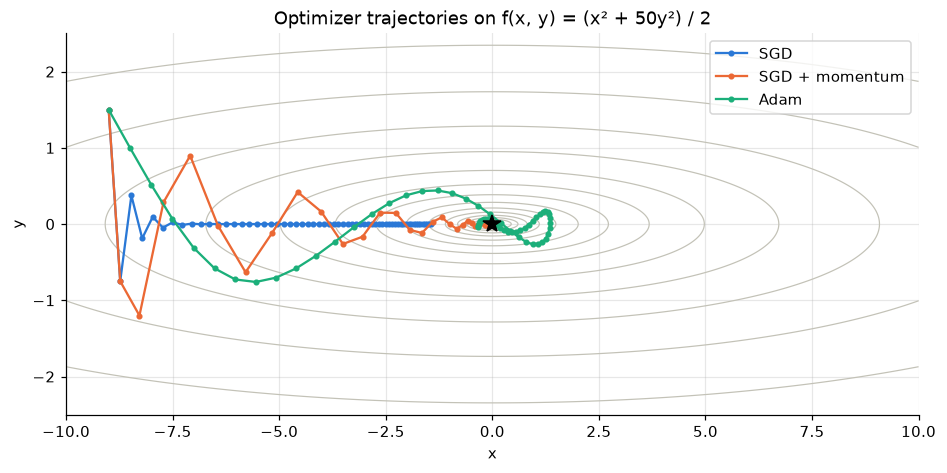

SGD             f after 60 steps: 1.05e+00
SGD + momentum  f after 60 steps: 1.52e-07
Adam            f after 60 steps: 9.17e-02


In [9]:
def f(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)


def trajectory(make_opt, steps=60, start=(-9.0, 1.5)):
    p = torch.tensor(start, requires_grad=True)
    opt = make_opt([p])
    path = [p.detach().clone()]
    for _ in range(steps):
        opt.zero_grad()
        f(p).backward()
        opt.step()
        path.append(p.detach().clone())
    return torch.stack(path).numpy()


paths = {
    "SGD": trajectory(lambda p: SGDMomentum(p, lr=0.03)),
    "SGD + momentum": trajectory(lambda p: SGDMomentum(p, lr=0.03, momentum=0.7)),
    "Adam": trajectory(lambda p: Adam(p, lr=0.5)),
}

xs, ys = np.meshgrid(np.linspace(-10, 10, 300), np.linspace(-2.5, 2.5, 300))
plt.figure(figsize=(10, 4.5))
plt.contour(xs, ys, 0.5 * (xs ** 2 + 50 * ys ** 2), levels=np.logspace(-1, 2.4, 14), colors="#c3c2b7", linewidths=0.8)
for name, path in paths.items():
    plt.plot(path[:, 0], path[:, 1], marker="o", ms=3, lw=1.5, label=name)
plt.plot(0, 0, "k*", ms=12)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Optimizer trajectories on f(x, y) = (x² + 50y²) / 2")
plt.legend()
plt.show()

for name, path in paths.items():
    print(f"{name:<15} f after 60 steps: {f(path[-1]):.2e}")

Plain SGD zig-zags across the valley at first, because a step of 0.03 is large for the steep $y$ direction and keeps overshooting $y = 0$. Once $y$ settles it only crawls along $x$, where the gradient is small, and after 60 steps it is still around $x = -1.4$. Momentum also oscillates in $y$, but it builds up speed along $x$ where the gradient always points the same way, so it reaches the minimum much faster ($f \approx 10^{-7}$). Adam divides each gradient component by its running size, so its first steps move about the same amount in $x$ and $y$ (a diagonal line) and ignore that $y$ is 50 times steeper; near the minimum it keeps circling instead of settling, because with a fixed learning rate its steps don't shrink much.

## 2(c) Training a small CNN with each optimizer

The small CNN above (three conv + max-pool blocks, then two linear layers) is trained for 15 epochs with plain SGD, SGD with momentum ($\mu = 0.9$) and Adam, each at learning rates 0.001, 0.01 and 0.1. Everything else is kept the same: same initial weights, batch size 128 and the same order of batches.

In [10]:
def evaluate_model(model, X, y, batch_size=1000):
    model.eval()
    correct = 0
    with torch.no_grad():
        for xb, yb in batches(X, y, batch_size):
            correct += (model(xb).argmax(1) == yb).sum().item()
    return correct / len(X)


def train_model(model, opt, epochs, batch_size=128):
    gen = torch.Generator().manual_seed(SEED)
    train_loss, val_acc = [], []
    for _ in range(epochs):
        model.train()
        total = 0.0
        for xb, yb in batches(X_train, y_train, batch_size, shuffle=True, gen=gen):
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.detach() * len(yb)
        train_loss.append(total.item() / len(X_train))
        val_acc.append(evaluate_model(model, X_val, y_val))
    return train_loss, val_acc


optimizers = {
    "SGD": lambda p, lr: SGDMomentum(p, lr),
    "SGD + momentum": lambda p, lr: SGDMomentum(p, lr, momentum=0.9),
    "Adam": lambda p, lr: Adam(p, lr),
}
lrs = [0.001, 0.01, 0.1]
results = {}
for name, make_opt in optimizers.items():
    for lr in lrs:
        set_seed()
        model = small_cnn()
        results[name, lr] = train_model(model, make_opt(model.parameters(), lr), n_epochs(15))

print(f"{'validation accuracy':<20}" + "".join(f"{'lr = ' + str(lr):>12}" for lr in lrs))
for name in optimizers:
    print(f"{name:<20}" + "".join(f"{results[name, lr][1][-1]:>12.2%}" for lr in lrs))

validation accuracy   lr = 0.001   lr = 0.01    lr = 0.1
SGD                       28.96%      61.12%      66.58%
SGD + momentum            63.56%      75.48%      51.14%
Adam                      75.20%      50.02%       9.34%


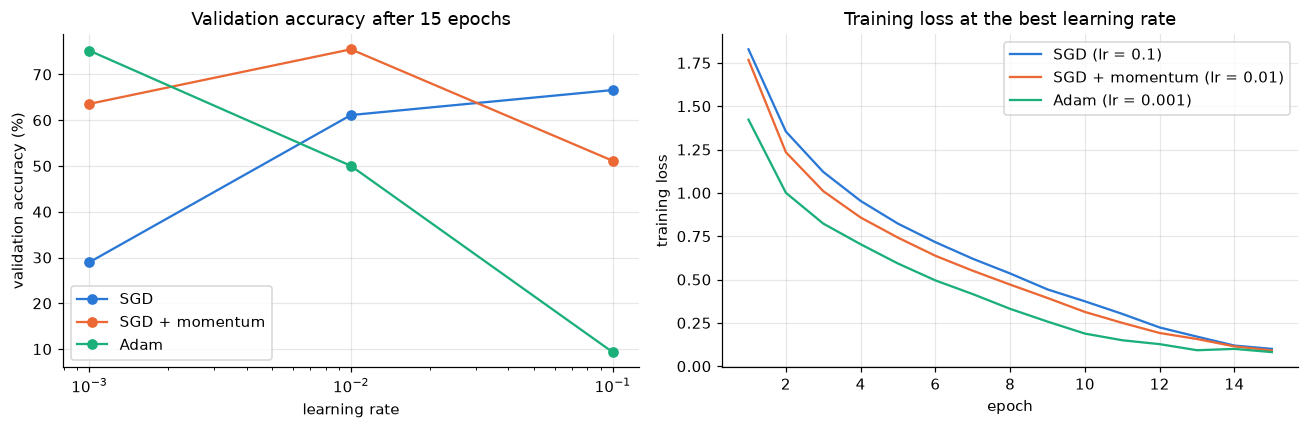

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for name in optimizers:
    accs = [results[name, lr][1][-1] * 100 for lr in lrs]
    ax1.semilogx(lrs, accs, marker="o", label=name)
    best_lr = lrs[int(np.argmax(accs))]
    train_loss = results[name, best_lr][0]
    ax2.plot(range(1, len(train_loss) + 1), train_loss, label=f"{name} (lr = {best_lr})")
ax1.set(xlabel="learning rate", ylabel="validation accuracy (%)", title="Validation accuracy after 15 epochs")
ax2.set(xlabel="epoch", ylabel="training loss", title="Training loss at the best learning rate")
ax1.legend()
ax2.legend()
plt.tight_layout()
plt.show()

Each optimizer has a different best learning rate: 0.1 for plain SGD (67%), 0.01 for SGD with momentum (75%) and 0.001 for Adam (75%). Plain SGD is far too slow with a small learning rate (29% at 0.001), while Adam is the most sensitive to large ones: it drops to 50% at 0.01 and diverges at 0.1 (9%, no better than guessing). Momentum with $\mu = 0.9$ acts like SGD with a 10 times larger learning rate, so its curve looks like SGD's shifted one step to the left. At the best rates Adam brings the training loss down fastest in the first epochs, but all three end at about the same training loss, so no optimizer wins everywhere and the learning rate has to be tuned for each one.

# Task 3: Regularization and residual connections

## 3(a) Regularization on 5k training images

To make overfitting easy to see, I train a small CNN with batch norm on only the first 5,000 training images and compare seven settings: baseline, weight decay (5e-4), dropout (p = 0.3 before both linear layers), random flip + crop (pad by 4 and crop back to 32×32), cutout (one random 8×8 square set to zero), mixup ($\alpha$ = 0.2) and all of them combined. Cutout and mixup are written by hand below; mixup blends two images, $\tilde x = \lambda x_i + (1-\lambda) x_j$ with $\lambda \sim \text{Beta}(\alpha, \alpha)$, and uses the same $\lambda$ to blend their losses.

I picked these strengths by trying a couple of values on the validation set. Every run uses SGD with momentum 0.9, learning rate 0.05 with cosine decay, batch size 128 and 150 epochs. Train accuracy is measured on the clean training images (no augmentation, eval mode), so it means the same thing for every setting.

In [12]:
def flip_crop(x, pad=4):
    n, _, h, w = x.shape
    flip = torch.rand(n, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    x = F.pad(x, (pad, pad, pad, pad))
    rows = torch.randint(0, 2 * pad + 1, (n, 1), device=x.device) + torch.arange(h, device=x.device)
    cols = torch.randint(0, 2 * pad + 1, (n, 1), device=x.device) + torch.arange(w, device=x.device)
    idx = torch.arange(n, device=x.device)[:, None, None, None]
    ch = torch.arange(3, device=x.device)[None, :, None, None]
    return x[idx, ch, rows[:, None, :, None], cols[:, None, None, :]]


def cutout(x, size=8):
    n, _, h, w = x.shape
    cy = torch.randint(0, h, (n, 1, 1), device=x.device)
    cx = torch.randint(0, w, (n, 1, 1), device=x.device)
    ys = torch.arange(h, device=x.device)[None, :, None]
    xs = torch.arange(w, device=x.device)[None, None, :]
    half = size // 2
    mask = (ys >= cy - half) & (ys < cy + half) & (xs >= cx - half) & (xs < cx + half)  # square may go past the border
    return x * ~mask[:, None]


def mixup(x, y, alpha):
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(len(x), device=x.device)
    return lam * x + (1 - lam) * x[perm], y, y[perm], lam


def fit(model, opt, epochs, X, y, augment=None, mixup_alpha=0.0, warmup_epochs=0, track_train_acc=False, batch_size=128):
    steps_per_epoch = math.ceil(len(X) / batch_size)
    warmup, total_steps = warmup_epochs * steps_per_epoch, epochs * steps_per_epoch
    # linear warmup, then cosine decay to zero (updated every step)
    lr_factor = lambda s: (s + 1) / warmup if s < warmup else 0.5 * (1 + math.cos(math.pi * (s - warmup) / max(1, total_steps - warmup)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)
    gen = torch.Generator().manual_seed(SEED)
    hist = {"train_loss": [], "train_acc": [], "val_acc": []}
    for _ in range(epochs):
        model.train()
        total = 0.0
        for xb, yb in batches(X, y, batch_size, shuffle=True, gen=gen):
            if augment:
                xb = augment(xb)
            if mixup_alpha:
                xb, ya, yb2, lam = mixup(xb, yb, mixup_alpha)
                out = model(xb)
                loss = lam * F.cross_entropy(out, ya) + (1 - lam) * F.cross_entropy(out, yb2)
            else:
                loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            sched.step()
            total += loss.detach() * len(xb)
        hist["train_loss"].append(total.item() / len(X))
        if track_train_acc:
            hist["train_acc"].append(evaluate_model(model, X, y))
        hist["val_acc"].append(evaluate_model(model, X_val, y_val))
    return hist

In [13]:
def bn_cnn(dropout=0.0):
    def block(c_in, c_out):
        return [nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2)]
    return nn.Sequential(
        *block(3, 32), *block(32, 64), *block(64, 128), nn.Flatten(),
        nn.Dropout(dropout), nn.Linear(128 * 4 * 4, 256), nn.ReLU(),
        nn.Dropout(dropout), nn.Linear(256, 10),
    ).to(device)


X_small, y_small = X_train[:5000], y_train[:5000]
configs = {
    "baseline": {},
    "weight decay": {"wd": 5e-4},
    "dropout": {"dropout": 0.3},
    "flip + crop": {"augment": flip_crop},
    "cutout": {"augment": cutout},
    "mixup": {"mixup_alpha": 0.2},
    "all combined": {"wd": 5e-4, "dropout": 0.3, "augment": lambda x: cutout(flip_crop(x)), "mixup_alpha": 0.2},
}

reg_hist = {}
for name, cfg in configs.items():
    set_seed()
    model = bn_cnn(cfg.get("dropout", 0.0))
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=cfg.get("wd", 0.0))
    reg_hist[name] = fit(model, opt, n_epochs(150), X_small, y_small, augment=cfg.get("augment"),
                         mixup_alpha=cfg.get("mixup_alpha", 0.0), track_train_acc=True)

print(f"{'setting':<15}{'train acc':>11}{'val acc':>10}{'gap':>8}")
for name, h in reg_hist.items():
    train_acc, val_acc = h["train_acc"][-1], h["val_acc"][-1]
    print(f"{name:<15}{train_acc:>11.1%}{val_acc:>10.1%}{train_acc - val_acc:>8.1%}")

setting          train acc   val acc     gap
baseline            100.0%     62.3%   37.7%
weight decay        100.0%     64.3%   35.7%
dropout             100.0%     67.7%   32.3%
flip + crop          99.8%     74.9%   25.0%
cutout              100.0%     65.0%   35.0%
mixup               100.0%     62.9%   37.1%
all combined         91.3%     75.1%   16.1%


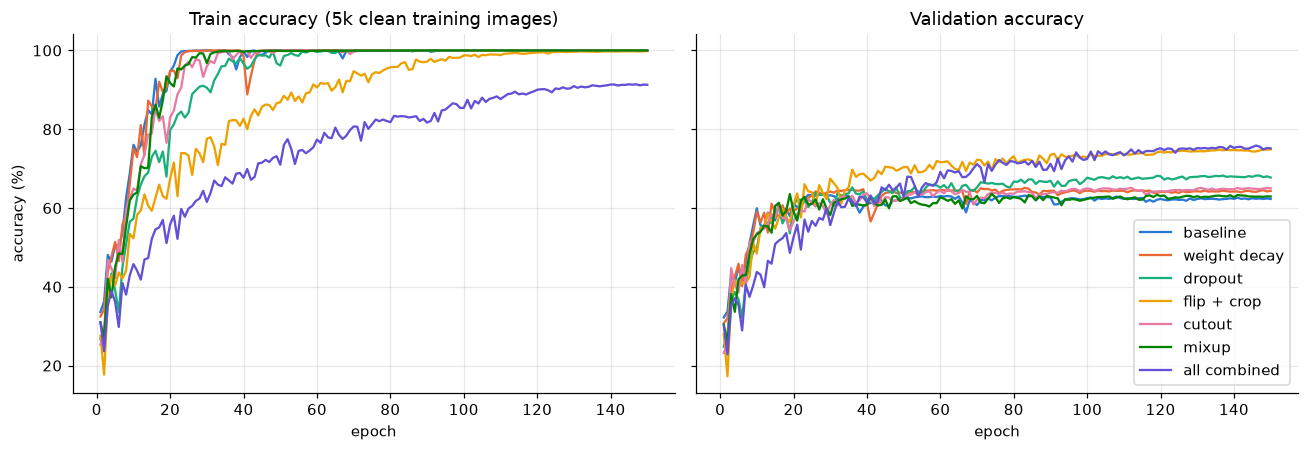

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for name, h in reg_hist.items():
    epochs = range(1, len(h["val_acc"]) + 1)
    ax1.plot(epochs, np.array(h["train_acc"]) * 100, lw=1.5, label=name)
    ax2.plot(epochs, np.array(h["val_acc"]) * 100, lw=1.5, label=name)
ax1.set(xlabel="epoch", ylabel="accuracy (%)", title="Train accuracy (5k clean training images)")
ax2.set(xlabel="epoch", title="Validation accuracy")
ax2.legend()
plt.tight_layout()
plt.show()

With only 5k images, the baseline memorises the training set (100% train accuracy) but reaches only 62% on validation, a gap of 38 points. Weight decay, dropout and cutout each help a little (64%, 68% and 65%), and mixup on its own makes almost no difference (63%); in all four the network still gets 100% on the training set, so with these mild settings they don't stop it from memorising. Flip + crop helps the most on its own (75%, gap 25 points), because it creates new but realistic versions of every image, which is exactly what a small dataset is missing. Combining everything reaches the same validation accuracy as flip + crop (75%) but with by far the smallest gap (16 points): the model can no longer fit the training set perfectly (91%), so it has to learn features that generalise, but it also learns much more slowly and needs many epochs.

## 3(b) Plain vs residual networks

These are the CIFAR networks from the ResNet paper: a 3×3 conv with 16 channels, then three stages of $n$ blocks with 16, 32 and 64 channels (the first block of stages 2 and 3 halves the image size with stride 2), then global average pooling and a linear layer. Each block is two 3×3 conv + batch norm layers, so the depth is $6n + 2$; I use $n = 1, 3, 9$ for depths 8, 20 and 56. Weights use Kaiming init.

The only difference between the two families is the shortcut: a residual block adds its input to its output before the last ReLU, a plain block doesn't. When the number of channels doubles, the shortcut takes every second pixel and pads the new channels with zeros, so it has no weights and both families have exactly the same parameters. All six networks are trained for 30 epochs with SGD (momentum 0.9, weight decay $10^{-4}$), batch size 128 and flip + crop augmentation. The learning rate warms up from 0 to 0.1 during the first epoch and then follows a cosine decay; without the warmup the 56-layer networks were unstable in the first epoch.

In [15]:
class Block(nn.Module):
    def __init__(self, c_in, c_out, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.residual, self.stride, self.extra = residual, stride, c_out - c_in

    def forward(self, x):
        out = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
        if self.residual:
            shortcut = x[:, :, ::self.stride, ::self.stride]
            out = out + F.pad(shortcut, (0, 0, 0, 0, 0, self.extra))  # zero-pad the new channels
        return F.relu(out)


class CifarNet(nn.Module):
    def __init__(self, depth, residual, widths=(16, 32, 64)):
        super().__init__()
        n = (depth - 2) // 6
        c_in = widths[0]
        layers = [nn.Conv2d(3, c_in, 3, padding=1, bias=False), nn.BatchNorm2d(c_in), nn.ReLU()]
        for stage, c_out in enumerate(widths):
            for i in range(n):
                layers.append(Block(c_in, c_out, 2 if stage > 0 and i == 0 else 1, residual))
                c_in = c_out
        self.features = nn.Sequential(*layers)
        self.fc = nn.Linear(widths[-1], 10)
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        return self.fc(self.features(x).mean(dim=(2, 3)))


depth_hist = {}
for residual in [False, True]:
    for depth in [8, 20, 56]:
        set_seed()
        model = CifarNet(depth, residual).to(device)
        opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
        name = f"{'ResNet' if residual else 'plain'}-{depth}"
        depth_hist[name] = fit(model, opt, n_epochs(30), X_train, y_train, augment=flip_crop, warmup_epochs=1)
        print(f"{name:<10} params {sum(p.numel() for p in model.parameters()):>7,}   "
              f"final train loss {depth_hist[name]['train_loss'][-1]:.3f}   val acc {depth_hist[name]['val_acc'][-1]:.2%}")

plain-8    params  75,290   final train loss 0.375   val acc 85.02%


plain-20   params 269,722   final train loss 0.205   val acc 87.72%


plain-56   params 853,018   final train loss 0.964   val acc 65.40%


ResNet-8   params  75,290   final train loss 0.390   val acc 84.54%


ResNet-20  params 269,722   final train loss 0.154   val acc 88.88%


ResNet-56  params 853,018   final train loss 0.081   val acc 89.96%


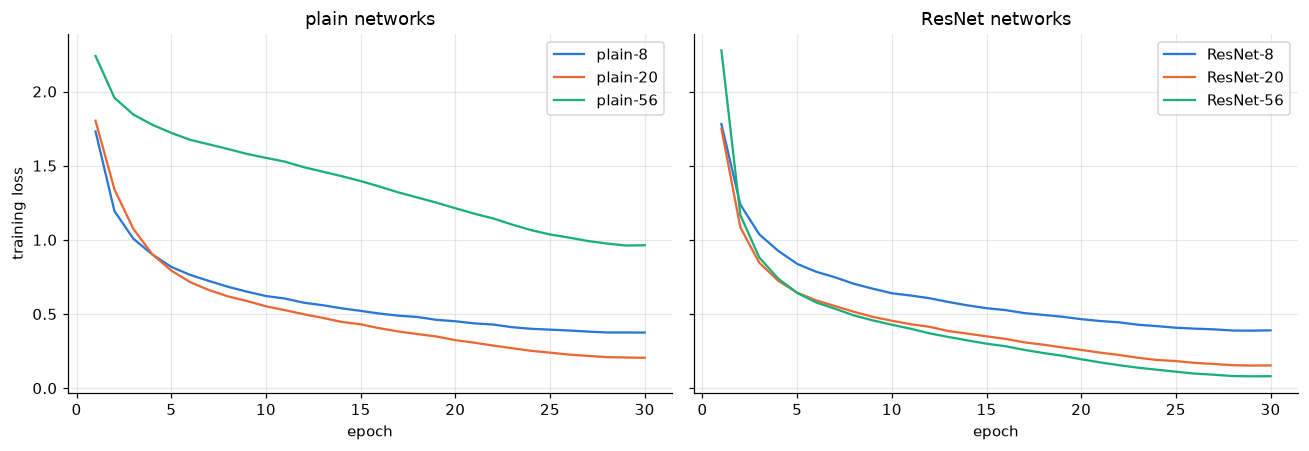

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, family in zip(axes, ["plain", "ResNet"]):
    for depth in [8, 20, 56]:
        loss = depth_hist[f"{family}-{depth}"]["train_loss"]
        ax.plot(range(1, len(loss) + 1), loss, label=f"{family}-{depth}")
    ax.set(xlabel="epoch", title=f"{family} networks")
    ax.legend()
axes[0].set_ylabel("training loss")
plt.tight_layout()
plt.show()

For the plain networks, going from 8 to 20 layers lowers the training loss, but the 56-layer plain network is much worse than both (0.96 vs 0.21 for plain-20 after 30 epochs). Since this is the training loss, it isn't overfitting: the deeper plain network is just harder to optimise, even though it could in theory copy the 20-layer network and make its extra layers do nothing. This is the degradation problem. With shortcuts it goes away and deeper is better: ResNet-56 gets the lowest training loss (0.08), then ResNet-20 (0.15) and ResNet-8 (0.39), with validation accuracy in the same order (90.0%, 88.9%, 84.5%). A residual block only has to learn a correction on top of its input, and the shortcut gives the gradient a direct path back to the early layers, so adding layers doesn't make training harder; at depth 8 both families behave the same because a shallow network is easy to train either way.

# Task 4: Best CNN (at most 500k parameters and 20 epochs)

My final model is a wider and shallower version of the residual network from 3(b): channel widths 32/64/96 with two residual blocks per stage (depth 14, 473k parameters). It is trained for 20 epochs with SGD (Nesterov momentum 0.9, weight decay $5 \times 10^{-4}$), a learning rate that warms up to 0.1 in the first epoch and then follows a cosine decay, and flip + crop + cutout augmentation. I tried a few widths and depths under the limit on the validation split (for example ResNet-32 with 16/32/64 channels got 90.4% and widths 24/48/96 got 89.8%) and kept the best one.

For the ablation I change one design choice at a time and retrain from the same initial weights: no shortcuts, no augmentation, no weight decay, and Adam (learning rate 0.002) instead of SGD.

In [ ]:
def train_task4(residual=True, augment=lambda x: cutout(flip_crop(x)), wd=5e-4, adam=False):
    set_seed()
    model = CifarNet(14, residual, widths=(32, 64, 96)).to(device)
    if adam:
        opt = torch.optim.Adam(model.parameters(), lr=2e-3, weight_decay=wd)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=wd)
    return model, fit(model, opt, n_epochs(20), X_train, y_train, augment=augment, warmup_epochs=1)


final_model, final_hist = train_task4()
print(f"parameters: {sum(p.numel() for p in final_model.parameters()):,}")

ablation = {
    "final model": final_hist,
    "no shortcuts": train_task4(residual=False)[1],
    "no augmentation": train_task4(augment=None)[1],
    "no weight decay": train_task4(wd=0.0)[1],
    "Adam instead of SGD": train_task4(adam=True)[1],
}
base = final_hist["val_acc"][-1]
print(f"{'setting':<22}{'val acc':>9}{'change':>9}")
for name, h in ablation.items():
    print(f"{name:<22}{h['val_acc'][-1]:>9.2%}{h['val_acc'][-1] - base:>+9.2%}")

In [ ]:
plt.figure(figsize=(7, 4))
for name, h in ablation.items():
    plt.plot(range(1, len(h["val_acc"]) + 1), np.array(h["val_acc"]) * 100, label=name)
plt.xlabel("epoch")
plt.ylabel("validation accuracy (%)")
plt.title("Task 4 ablation")
plt.legend()
plt.show()

INTERP_4A

## Test accuracy

This is the only place the test set is used. It is normalised with the training statistics and the final model is evaluated once (skipped in `QUICK_RUN` mode).

In [ ]:
if not QUICK_RUN:
    test = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)
    X_test = normalize(torch.from_numpy(test.data).permute(0, 3, 1, 2).float() / 255).to(device)
    y_test = torch.tensor(test.targets).to(device)
    print(f"test accuracy: {evaluate_model(final_model, X_test, y_test):.2%}")

INTERP_4B